In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# import dataset

In [2]:
!rm *.zip *.txt
!curl https://archive.ics.uci.edu/static/public/236/seeds.zip -o seeds.zip
!unzip seeds.zip
!ls

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  9432    0  9432    0     0  20269      0 --:--:-- --:--:-- --:--:-- 20283
Archive:  seeds.zip
 extracting: seeds_dataset.txt       
sample_data  seeds_dataset.txt	seeds.zip


In [3]:
df = pd.read_csv('seeds_dataset.txt', delim_whitespace=True, header=None)
display(df.head())

/tmp/ipython-input-3433391131.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv('seeds_dataset.txt', delim_whitespace=True, header=None)


,0,1,2,3,4,5,6,7
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


# handling duplicates

In [4]:
df.drop_duplicates(subset=range(7), inplace=True)

In [5]:
df.isnull().sum()

,0
0,0
1,0
2,0
3,0
4,0
5,0
6,0
7,0


In [6]:
X, y = df[df.columns[:-1]], df[df.columns[-1]]

# Kmeans clustering implementation

In [7]:
class KMeansClustering:
    def __init__(self, k=3, max_iterations=100):
        self.k = k
        self.max_iterations = max_iterations
        self.centroids = []
        self.labels = None
        self.inertia = None

    @staticmethod
    def _kmeans_plus_plus_initialize(X: np.ndarray, k: int):
        n_samples, _ = X.shape
        centroids = np.zeros((k, X.shape[1]))
        centroids[0] = X[np.random.randint(n_samples)]

        for i in range(1, k):
            distances = np.min(np.linalg.norm(X[:, np.newaxis] - centroids[:i], axis=2), axis=1)
            probabilities = distances**2 / np.sum(distances**2)
            cumulative_probabilities = np.cumsum(probabilities)
            r = np.random.rand()
            centroids[i] = X[np.searchsorted(cumulative_probabilities, r)]
        return centroids

    def fit(self, X: np.ndarray):
        X = np.asarray(X)
        n_samples, n_features = X.shape
        self.centroids = self._kmeans_plus_plus_initialize(X, self.k)

        for _ in range(self.max_iterations):
            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
            self.labels = np.argmin(distances, axis=1)

            new_centroids = np.zeros((self.k, n_features))
            for i in range(self.k):
                points = X[self.labels == i]
                if len(points) > 0:
                    new_centroids[i] = np.mean(points, axis=0)
                else:
                    new_centroids[i] = X[np.random.randint(0, n_samples)]

            if np.allclose(self.centroids, new_centroids, atol=1e-6):
                break
            self.centroids = new_centroids

        self.inertia = np.sum((X - self.centroids[self.labels])**2)


# clustering on dataset

In [8]:
impl_cluster = KMeansClustering(k=3)
impl_cluster.fit(X.values)
impl_labels = impl_cluster.labels
# number of points in each cluster
print('counts of points in clusters')
print(np.unique(impl_labels, return_counts=True))
print('centroidss: ')
print(impl_cluster.centroids)

counts of points in clusters
(array([0, 1, 2]), array([61, 72, 77]))
centroidss: 
[[18.72180328 16.29737705  0.88508689  6.20893443  3.72267213  3.60359016
   6.06609836]
 [14.64847222 14.46041667  0.87916667  5.56377778  3.27790278  2.64893333
   5.19231944]
 [11.96441558 13.27480519  0.8522      5.22928571  2.87292208  4.75974026
   5.08851948]]


# Visualization

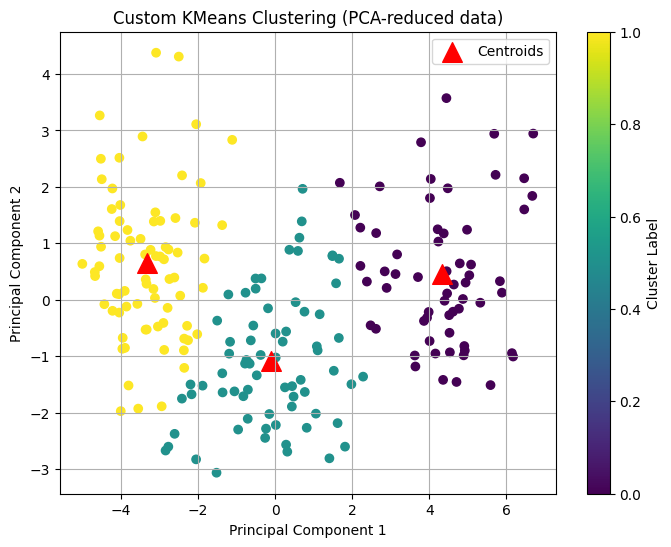

In [9]:
# PCA for 2 components
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

impl_centroids_pca = pca.transform(impl_cluster.centroids)

# Plot
plt.figure(figsize=(8, 6))

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=impl_labels, cmap='viridis')
plt.scatter(impl_centroids_pca[:, 0], impl_centroids_pca[:, 1], marker='^', s=200, c='red', label='Centroids')
plt.title('Custom KMeans Clustering (PCA-reduced data)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster Label')
plt.legend()
plt.grid(True)

# Evaluation

In [10]:
from sklearn.metrics import silhouette_score, rand_score

print(f'silhoutte score: {silhouette_score(X, impl_labels)}')
print(f'rand score: {rand_score(y, impl_labels)}')

silhoutte score: 0.4719337319126887
rand score: 0.8743677375256322


# Ground Truth Comparision

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

contingency_table = pd.crosstab(y, impl_labels, rownames=['True Class'], colnames=['Cluster'])
print("Contingency Table:")
print(contingency_table)

cluster_to_class = contingency_table.idxmax(axis=0)
print("\nCluster-to-Class Mapping:")
print(cluster_to_class)

impl_y_pred = impl_labels.copy()
for cluster_id, class_label in cluster_to_class.items():
    impl_y_pred[impl_labels == cluster_id] = class_label

impl_accuracy = accuracy_score(y, impl_y_pred)
impl_precision = precision_score(y, impl_y_pred, average='macro')
impl_recall = recall_score(y, impl_y_pred, average='macro')

print(f"\nAccuracy: {impl_accuracy:.4f}")
print(f"Precision: {impl_precision:.4f}")
print(f"Recall: {impl_recall:.4f}")

Contingency Table:
Cluster      0   1   2
True Class            
1            1  60   9
2           60  10   0
3            0   2  68

Cluster-to-Class Mapping:
Cluster
0    2
1    1
2    3
dtype: int64

Accuracy: 0.8952
Precision: 0.9000
Recall: 0.8952


# evaluation for sklearn

In [12]:
from sklearn.cluster import KMeans

kmeans_sklearn = KMeans(n_clusters=3, init='k-means++', random_state=42)
kmeans_sklearn.fit(X)
labels_sklearn = kmeans_sklearn.labels_

print(f'for my implementation')
print(f'silhoutte score: {silhouette_score(X, impl_labels):.4f}')
print(f'rand score: {rand_score(y, impl_labels):.4f}')
print('for sklearn')
print(f'silhoutte score: {silhouette_score(X, labels_sklearn):.4f}')
print(f'rand score: {rand_score(y, labels_sklearn):.4f}')

for my implementation
silhoutte score: 0.4719
rand score: 0.8744
for sklearn
silhoutte score: 0.4719
rand score: 0.8744


# Ground Truth Comparision

In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

contingency_table = pd.crosstab(y, labels_sklearn, rownames=['True Class'], colnames=['Cluster'])
print("Contingency Table:")
print(contingency_table)

cluster_to_class = contingency_table.idxmax(axis=0)
print("\nCluster-to-Class Mapping:")
print(cluster_to_class)

sk_y_pred = labels_sklearn.copy()
for cluster_id, class_label in cluster_to_class.items():
    sk_y_pred[labels_sklearn == cluster_id] = class_label

sk_accuracy = accuracy_score(y, sk_y_pred)
sk_precision = precision_score(y, sk_y_pred, average='macro')
sk_recall = recall_score(y, sk_y_pred, average='macro')

print(f"\nAccuracy: {sk_accuracy:.4f}")
print(f"Precision: {sk_precision:.4f}")
print(f"Recall: {sk_recall:.4f}")

Contingency Table:
Cluster      0   1   2
True Class            
1            1   9  60
2           60   0  10
3            0  68   2

Cluster-to-Class Mapping:
Cluster
0    2
1    3
2    1
dtype: int64

Accuracy: 0.8952
Precision: 0.9000
Recall: 0.8952


# model performance comparision

In [14]:
print(f'''
my implementation
    accuracy: {impl_accuracy:.4f}
    precision: {impl_precision:.4f}
    recall: {impl_recall:.4f}
''')
print(f'''
sklearn:
    accuracy: {sk_accuracy:.4f}
    precision: {sk_precision:.4f}
    recall: {sk_recall:.4f}
''')


my implementation
    accuracy: 0.8952
    precision: 0.9000
    recall: 0.8952


sklearn:
    accuracy: 0.8952
    precision: 0.9000
    recall: 0.8952



# Visualization

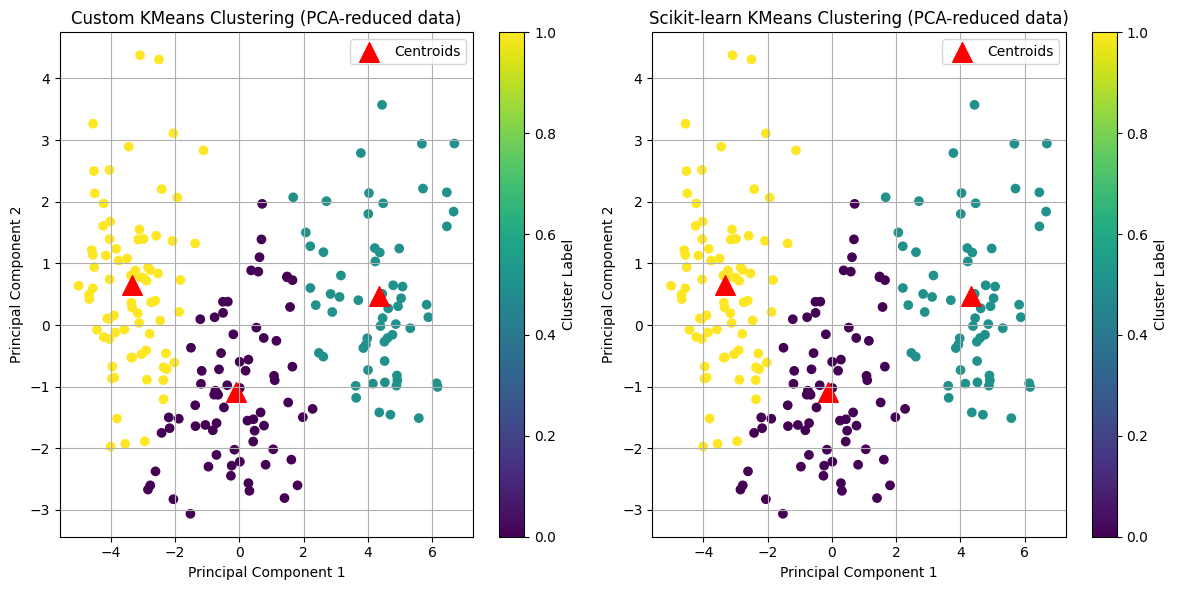

In [15]:
centroids_sklearn_pca = pca.transform(kmeans_sklearn.cluster_centers_)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=impl_y_pred, cmap='viridis')
plt.scatter(impl_centroids_pca[:, 0], impl_centroids_pca[:, 1], marker='^', s=200, c='red', label='Centroids')
plt.title('Custom KMeans Clustering (PCA-reduced data)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster Label')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=sk_y_pred, cmap='viridis')
plt.scatter(centroids_sklearn_pca[:, 0], centroids_sklearn_pca[:, 1], marker='^', s=200, c='red', label='Centroids')
plt.title('Scikit-learn KMeans Clustering (PCA-reduced data)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster Label')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()